# A small covariance experiment with Rafael's shear maps

**Thanks to Rafael Gomes for these CosmoGrid maps, and to Oliver Friedrich
and Tim Eifler for the [precision-matrix expansion](https://arxiv.org/abs/1703.07786).**
This experiment asks a limited but useful question: can a Gaussian reference
covariance describe the second- and third-order fluctuations measured from
these maps closely enough to attempt a precision expansion?

We measure coarse aperture moments, then compare a fixed Gaussian reference,
a simulation correction, and a separate validation sample. The reference
uses an aperture covariance estimated from a third group of simulations.
Thus it is a **Gaussian moment calculation calibrated on separate maps**,
not the independent analytic CosmoLike covariance we ultimately want to
correct. A successful test here would not calibrate the DES likelihood.

Follow [EXAMPLE_COVARIANCE_PME.ipynb](EXAMPLE_COVARIANCE_PME.ipynb) first for
the two-by-two noisy-square calculation. The
[notes](notes/covariance_from_simulations/covariance_from_simulations.pdf)
derive its assumptions. Here the inputs are real simulated shear fields,
but the measurement is intentionally much smaller than Rafael's published
xi/finite-triangle Map3 estimator.

## 1. Measure once; study the small saved table repeatedly

Run this bounded pilot from Cocoa. It reads four noise labels, cut zero,
and at most 48 run labels. It measures all four source-bin slots:

```bash
python projects/des_3pcf/scripts/measure_covariance_maps.py --max-runs 48
```

Once the download has settled, this separate command applies **the same
pilot measurement** to every complete map currently present:

```bash
python projects/des_3pcf/scripts/measure_covariance_maps.py --all
```

The driver limits OpenMP to four and BLAS to one, opens one map at a time,
and writes small text tables under `chains/`. It does not copy the map files,
create per-map plots, or run the full three-point correlation estimator.
A file whose size or timestamp changes is deferred. A settled local file
is not a producer-certified file; input checksums and release metadata are
still needed. The covariance analysis reads only those measured tables. The final bounded
input check additionally reads 8,192 pixel positions from twenty files of
each of two run labels, to investigate what changes between noise labels.

In [1]:
# Setup only: this cell loads the plotting and statistical routines.
# No DES map, cosmological model or covariance calculation is started here.
# Run this notebook from the des_3pcf directory so the paths below refer to
# this checkout rather than another project's compiled interface.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

# Set workers before importing NumPy. This small example needs one worker;
# BLAS must remain single-threaded in the Cocoa workflow.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_precision_wrappers as nw

# A notebook kernel may already have imported a BLAS library. Limit those
# loaded libraries too; environment variables alone would not change them.
blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
# The shared plotting package accepts ordinary arrays and does not run
# this project's native interface. Its name begins with a digit, so importlib
# loads it by its full module name.
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

In [3]:
# The choice is explicit: changing to covariance_maps_full reads the larger
# run's table. Running this notebook never measures another map.
MEASUREMENT = PROJECT / "chains" / "covariance_maps_pilot"
map_vectors = np.loadtxt(fname=MEASUREMENT / "moments.txt", ndmin=2)
primary_apertures = np.loadtxt(
    fname=MEASUREMENT / "primary_apertures.txt",
    ndmin=2,
)
# Sorting by IDs also handles a later pass appending newly arrived files.
map_order = np.lexsort((map_vectors[:, 2], map_vectors[:, 1], map_vectors[:, 0]))
map_vectors = map_vectors[map_order]
primary_order = np.argsort(a=primary_apertures[:, 0])
primary_apertures = primary_apertures[primary_order]
centers = np.loadtxt(fname=MEASUREMENT / "centers.txt", ndmin=2)
print((MEASUREMENT / "measurement.txt").read_text())
print("Saved moment table shape:", map_vectors.shape)
print("Retained radial filter weight, minimum at each radius:",
      np.min(a=centers[:, 3:], axis=0))
# IDs are the first three columns. The remaining 16 columns are measurements.
run_ids = map_vectors[:, 0].astype(int)
cut_ids = map_vectors[:, 1].astype(int)
draw_ids = map_vectors[:, 2].astype(int)
values = map_vectors[:, 3:]
assert values.shape[1] == 16
assert np.all(np.isfinite(values))

Selected files: 192
Measured files: 192
Newly measured in this pass: 0
Deferred files: 0
Elapsed seconds: 0.548
OpenMP limit: 4
BLAS workers: 1
Pixel convention: RING/equatorial, geometry inference
Shear basis: g1 east, g2 +45deg toward north, UNCONFIRMED
Parent IDs: run labels, independence UNCONFIRMED
Q radii: 30,60 arcmin; truncated at 4R; 64 fixed centers
Rows: 8 raw squared moments then 8 raw cubed moments
No noise self-product subtraction; no catalogue weights
These are diagnostic moments, not the published xi/Map3 estimator.

Saved moment table shape: (192, 19)
Retained radial filter weight, minimum at each radius: [0.98785809 0.98868762]


## 2. What did the driver measure?

Around each of 64 fixed centers, tangential shear is integrated with a
Gaussian aperture filter. Its radius $R$ is either 30 or 60 arcminutes:

$$Q_R(\theta)=\frac{\theta^2}{4\pi R^4}
\exp\!\left(-\frac{\theta^2}{2R^2}\right).$$

Angles in the calculation are in radians. Each retained HEALPix pixel
contributes its equal solid angle and its tangential shear:

$$a_{bRc}=\Omega_{\rm pix}\sum_{j\ {
m retained}}
 Q_R(\theta_{cj})\,\gamma_{t,bj;c}.$$

Here $b$ labels a source-bin slot, $c$ a center, and $j$ a pixel. The bearing
used to rotate the shear is measured **at the pixel toward the center**.
The integral stops at four radii, retaining about 99.698% of the radial
weight in the unmasked flat-sky formula. Centers are chosen using geometry
alone and must retain at least 99% of that truncated weight at both radii.
The code does not renormalize away missing sky.

Average the squared aperture values over the same centers:

$$d_{2,bR}=\frac1{64}\sum_{c=1}^{64}a_{bRc}^2.$$

Separately average their cubes:

$$d_{3,bR}=\frac1{64}\sum_{c=1}^{64}a_{bRc}^3.$$

Four source bins and two radii give eight second-order entries and eight
third-order entries. Their covariance includes all cross-bin and
second/third-order cross-correlations.

**Measurement limits.** These raw moments retain pixel-noise self-products.
They use equal pixel weights, only 64 centers, and auto-bin moments. They
are not the catalogue pair/triple estimator, and they do not include the
published triangle cuts or all mixed-bin Map3 entries. The RING ordering is
supported by geometry. The assumed equatorial shear signs and the meaning
of run/cut/noise labels still need producer confirmation. NSIDE 512 differs
from the methods paper's NSIDE 1024. These choices remain fixed throughout
this diagnostic; none was adjusted to improve the covariance comparison.

## 3. Separate reference, correction, and validation parents

For the first precision test we use only cut zero, draw zero of each run.
No number of additional noise files increases this independent-parent count.
We assign runs by their integer ID modulo three **before inspecting the
results**. Remainder zero calibrates the Gaussian reference; remainder one
estimates its correction; remainder two validates it. All descendants of a
run retain that assignment.

This is a conditional statistical interpretation: different run labels must
really be independent parent simulations for the independence claims to
hold. Filename differences alone do not prove it. The other cuts are saved,
but do not enter this primary test as extra independent skies.

In [4]:
# Each parent contributes exactly one noisy survey vector in this test.
primary_selection = (cut_ids == 0) & (draw_ids == 0)
primary_runs = run_ids[primary_selection]
primary_vectors = values[primary_selection]
assert np.unique(primary_runs).size == primary_runs.size
np.testing.assert_array_equal(primary_apertures[:, 0].astype(int), primary_runs)
reference_selection = primary_runs % 3 == 0
correction_selection = primary_runs % 3 == 1
validation_selection = primary_runs % 3 == 2
reference_values = primary_vectors[reference_selection]
correction_values = primary_vectors[correction_selection]
validation_values = primary_vectors[validation_selection]
reference_apertures = primary_apertures[reference_selection, 1:]
print("Reference parents:", np.count_nonzero(reference_selection))
print("Correction parents:", np.count_nonzero(correction_selection))
print("Validation parents:", np.count_nonzero(validation_selection))
print("Rows:", primary_vectors.shape[1])
# Center each sample using its own mean. np.cov divides by N-1 here.
correction_covariance = np.cov(m=correction_values, rowvar=False, ddof=1)
validation_covariance = np.cov(m=validation_values, rowvar=False, ddof=1)

Reference parents: 16
Correction parents: 16
Validation parents: 16
Rows: 16


## 4. Build a Gaussian reference with the actual aperture geometry

Let $K_{ij}$ be the covariance of two aperture values. Its indices include
source bin, radius, and center. We estimate this matrix using only the
reference parents. A Gaussian field has no connected four- or six-point
correlations, so products of its aperture values reduce to sums of pairs.

For the squared measurements, subtracting the product of the two means
leaves two pairings:

$$\operatorname{Cov}(a_i^2,a_j^2)=2K_{ij}^2.$$

For the cubed measurements there are six pairings with all three factors
crossing between the two positions, and nine with one cross-pair:

$$\operatorname{Cov}(a_i^3,a_j^3)
 =6K_{ij}^3+9K_{ii}K_{jj}K_{ij}.$$

A squared measurement correlated with a cubed measurement contains five
zero-mean Gaussian factors. Their expectation vanishes:

$$\operatorname{Cov}(a_i^2,a_j^3)=0.$$

The moment covariance averages these expressions over **both** sets of
centers. Keeping all pairs accounts for overlapping apertures and their
correlations in this reference. Treating the 64 centers as independent
would drop these terms and would change the model.

This Gaussian reference omits connected non-Gaussian fluctuations. Its
input $K$ is estimated, so the reference also carries finite-calibration
noise and plug-in bias from powers of that estimate. It is held fixed and
independent of the correction and validation groups. Do not describe it as
a noise-free cosmological covariance or infer a simulation saving for the
production analysis from this experiment.

Gaussian-reference standard deviations: [1.01233616e-06 2.97395916e-07 1.33906531e-06 3.85119796e-07
 1.50468059e-06 5.06135994e-07 2.36820299e-06 7.85059904e-07
 1.75170314e-09 3.22620679e-10 3.81882358e-09 6.45943709e-10
 4.75262370e-09 6.18634771e-10 7.73016826e-09 1.54175111e-09]


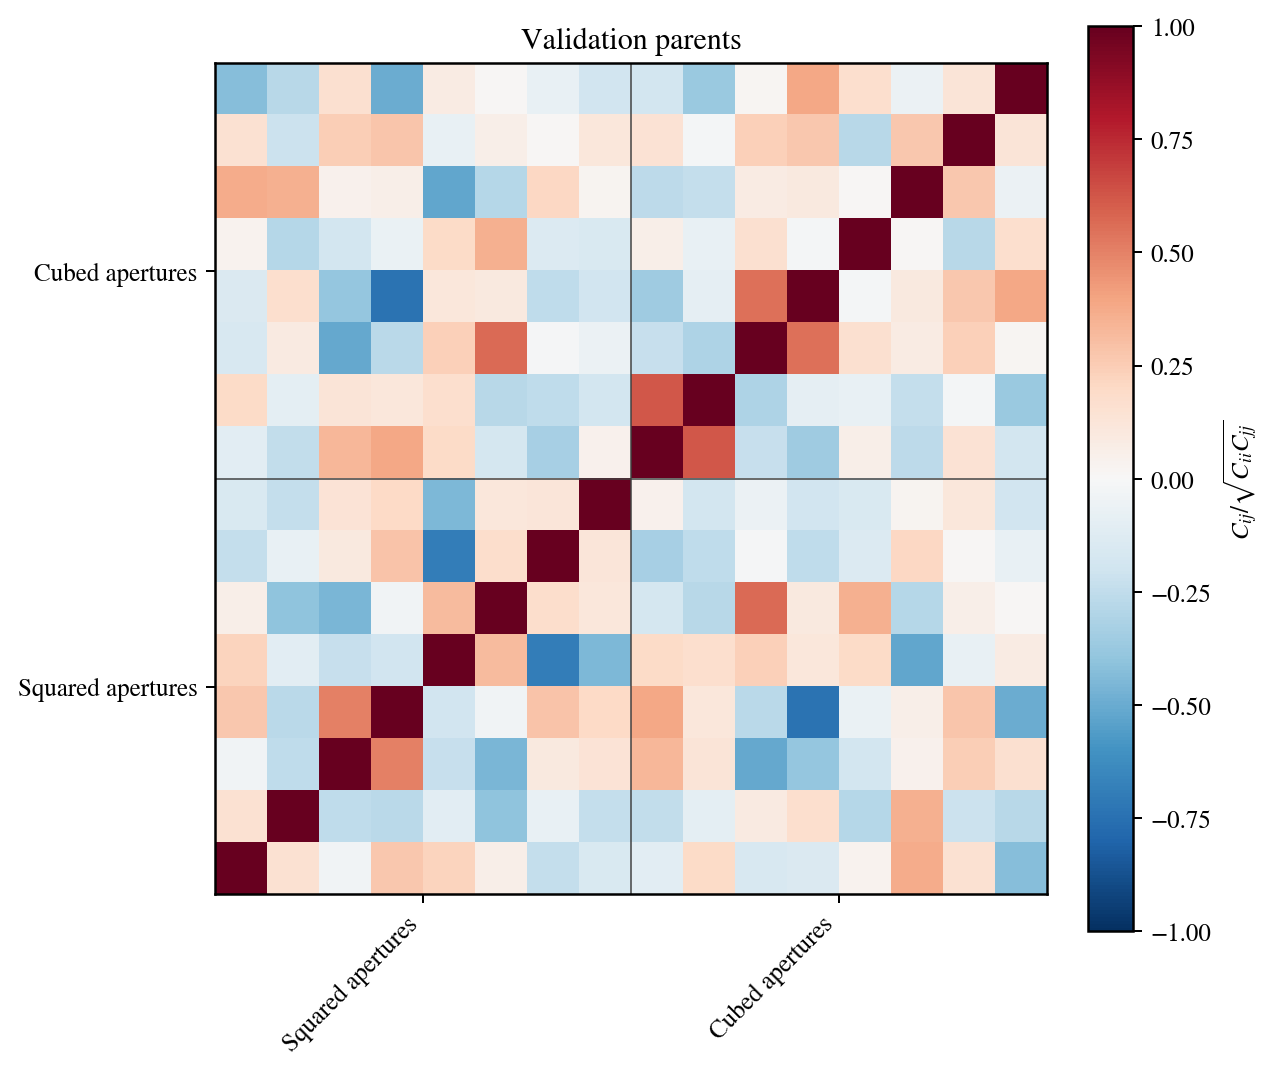

In [5]:
# The 512 aperture columns are ordered as [4 sources, 2 radii, 64 centers].
# Their sample covariance has blocks of 64 by 64 center correlations.
aperture_covariance = np.cov(m=reference_apertures, rowvar=False, ddof=1)
gaussian_model = np.zeros(shape=(16, 16))
for first_row in range(8):
    first_slice = slice(64 * first_row, 64 * (first_row + 1))
    first_variances = np.diag(v=aperture_covariance)[first_slice]
    for second_row in range(8):
        second_slice = slice(64 * second_row, 64 * (second_row + 1))
        second_variances = np.diag(v=aperture_covariance)[second_slice]
        cross = aperture_covariance[first_slice, second_slice]
        # These powers are ELEMENTWISE Gaussian pair contractions, not the
        # matrix square used in the PME correction. The final mean sums over
        # both centers and divides by 64 squared.
        gaussian_model[first_row, second_row] = 2. * np.mean(a=cross**2)
        one_cross_pair = 9. * np.outer(first_variances, second_variances) * cross
        three_cross_pairs = 6. * cross**3
        gaussian_model[first_row + 8, second_row + 8] = np.mean(
            a=one_cross_pair + three_cross_pairs,
        )
print("Gaussian-reference standard deviations:", np.sqrt(np.diag(gaussian_model)))
# The square/cube cross block is zero only in the reference. It is retained
# in both measured covariances and can therefore expose missing physics.
plots.plot_correlation(
    covariance=validation_covariance,
    labels=["Validation parents", "Reference"],
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
)

## 5. Inspect the model discrepancy before trusting a correction

Whiten the covariance using the Gaussian reference. An eigenvalue of one
means the same variance as the reference in that direction. The residual
subtracts one. For the **true** covariance the inverse series needs every
residual eigenvalue between minus one and plus one.

Here both correction and validation eigenvalues are noisy sample estimates.
They diagnose a possible model failure; they do not prove convergence or
nonconvergence of the unknown true series. In particular, a singular sample
necessarily has residual eigenvalues of minus one, even if its model is
accurate. Do not interpret sample rank deficiency as a physical instability.

Correction eigenvalue range: [8.90079122e-17 3.22906998e+00]
Validation eigenvalue range: [7.93012016e-17 4.47497535e+00]
Correction sample rank: 15


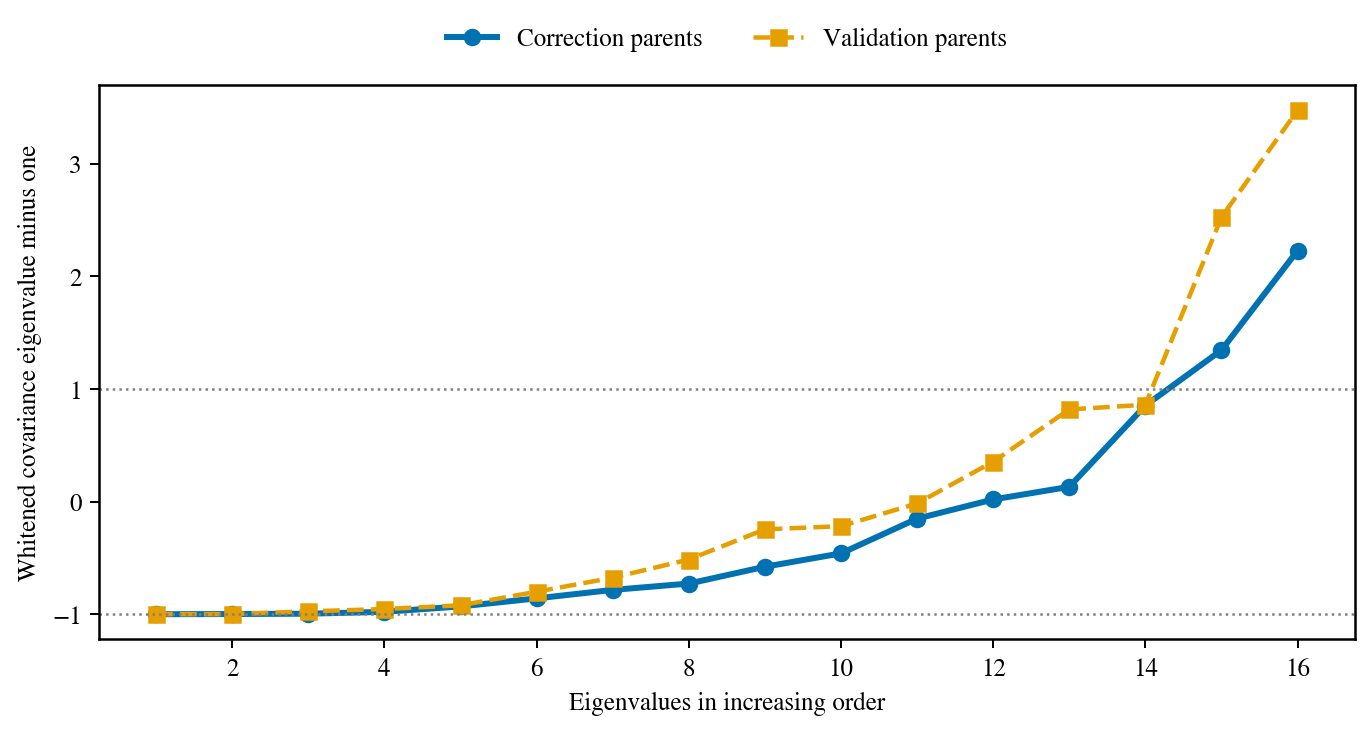

In [6]:
map_factor = np.linalg.cholesky(gaussian_model)
correction_whitened = nw.whiten_covariance(
    covariance=correction_covariance,
    factor=map_factor,
)
validation_whitened = nw.whiten_covariance(
    covariance=validation_covariance,
    factor=map_factor,
)
correction_eigenvalues = np.linalg.eigvalsh(correction_whitened)
validation_eigenvalues = np.linalg.eigvalsh(validation_whitened)
print("Correction eigenvalue range:", correction_eigenvalues[[0, -1]])
print("Validation eigenvalue range:", validation_eigenvalues[[0, -1]])
print("Correction sample rank:", np.linalg.matrix_rank(correction_whitened))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, 17), correction_eigenvalues - 1.,
        color="#0072B2", marker="o", linewidth=2.4, label="Correction parents")
ax.plot(np.arange(1, 17), validation_eigenvalues - 1.,
        color="#E69F00", marker="s", linewidth=1.8, linestyle="--",
        label="Validation parents")
ax.axhline(y=1., color="0.5", linestyle=":", linewidth=1.)
ax.axhline(y=-1., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Eigenvalues in increasing order")
ax.set_ylabel("Whitened covariance eigenvalue minus one")
# The legend occupies a separate strip above the axes, never the data area.
legend = ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02),
                   ncol=2, frameon=False)
fig.canvas.draw()
assert legend.get_window_extent().y0 > ax.get_window_extent().y1
plt.show()

## 6. Apply the noisy-square correction to the training covariance

We now repeat the operations taught in the small notebook: square the
whitened covariance by matrix multiplication, compute its trace, subtract
the Wishart bias term, and restore precision units. The shared routine
performs those steps. The Gaussian-summary assumption is provisional for
these nonlinear moments; we also calculate the independent-group product.

No validation vector enters a correction. No negative eigenvalue is clipped.
A nonpositive precision is reported as unsuitable for likelihood weighting.
Even a positive result still needs validation.

In [7]:
map_count = correction_values.shape[0]
map_precisions = {"Gaussian reference": np.linalg.solve(gaussian_model, np.eye(16))}
for order in (1, 2):
    estimate, diagnostics = nw.precision_expansion(
        analytic=gaussian_model,
        sample=correction_covariance,
        independent_count=map_count,
        order=order,
    )
    map_precisions[f"PME order {order}"] = estimate
    print("Order", order, diagnostics)
# The two halves are disjoint parents, not two noise draws of the same sky.
half = map_count // 2
first_half = np.cov(m=correction_values[:half], rowvar=False, ddof=1)
second_half = np.cov(m=correction_values[half:], rowvar=False, ddof=1)
map_precisions["Independent-group product"] = nw.split_precision_expansion(
    analytic=gaussian_model,
    sample_first=first_half,
    sample_second=second_half,
)
# Inspect positivity in dimensionless model coordinates, where unequal units
# of squared and cubed measurements cannot hide a negative direction.
for name, precision in map_precisions.items():
    polynomial = map_factor.T @ precision @ map_factor
    print(name, "minimum precision eigenvalue =", np.linalg.eigvalsh(polynomial)[0])

Order 1 {'estimated_residual_spectral_radius': 2.229069979969033, 'minimum_polynomial_eigenvalue': -1.229069979969031, 'independent_count': 16, 'order': 1}
Order 2 {'estimated_residual_spectral_radius': 2.229069979969033, 'minimum_polynomial_eigenvalue': -0.7282024487731419, 'independent_count': 16, 'order': 2}
Gaussian reference minimum precision eigenvalue = 0.9999999999999986
PME order 1 minimum precision eigenvalue = -1.2290699799690326
PME order 2 minimum precision eigenvalue = -0.72820244877314
Independent-group product minimum precision eigenvalue = -3.1087319779570324


## 7. Test the weights against untouched validation parents

For a fixed precision, a simple validation diagnostic is

$$q=\frac{\operatorname{tr}(\widehat\Psi\widehat C_{\rm val})}{p}.$$

The row count is $p=16$. The validation covariance uses its own estimated
mean and denominator $N_{\rm val}-1$, so its expectation is the true
covariance. Conditional on a fixed exact precision and independent parents,
the expected value of $q$ is one. Values above one indicate underestimated
fluctuations on average. Different directions can cancel in this trace;
$q$ near one does not establish correct parameter errors.

The uncertainty below removes one validation parent at a time, recomputes
the covariance and repeats the diagnostic. The jackknife standard error is

$$\sigma_q=\left[\frac{N_v-1}{N_v}\sum_{s=1}^{N_v}
 (q_{(-s)}-\bar q_{(-)})^2\right]^{1/2}.$$

Here $q_{(-s)}$ omits parent $s$, while the bar averages those results. This
measures sensitivity to the finite validation set with the precision held
fixed. It is not an exact confidence interval and does not include
reference-calibration noise, repeated training experiments, or a wrong
parent-independence assumption.

In [8]:
# Leaving out whole parents preserves the sky grouping. These calculations
# use only the small measured table, with the precision held fixed.
leave_one_out_covariances = []
for omitted in range(len(validation_values)):
    selected = np.arange(len(validation_values)) != omitted
    leave_one_out_covariances.append(
        np.cov(m=validation_values[selected], rowvar=False, ddof=1),
    )
print("Method | positive | validation q | jackknife standard error")
for name, precision in map_precisions.items():
    polynomial = map_factor.T @ precision @ map_factor
    positive = np.linalg.eigvalsh(polynomial)[0] > 0.
    q = np.trace(a=precision @ validation_covariance) / 16.
    leave_one_out = []
    for covariance in leave_one_out_covariances:
        leave_one_out.append(np.trace(a=precision @ covariance) / 16.)
    leave_one_out = np.asarray(leave_one_out)
    centered = leave_one_out - np.mean(a=leave_one_out)
    count = len(leave_one_out)
    jackknife_error = np.sqrt((count - 1.) / count * np.sum(a=centered**2))
    print(name, positive, f"{q:.4f}", f"{jackknife_error:.4f}")
# An indefinite result stays visible for diagnosis; its q does not validate
# a usable likelihood and must not be used to report parameter errors.

Method | positive | validation q | jackknife standard error
Gaussian reference True 1.0449 0.0800
PME order 1 False 1.0302 0.1390
PME order 2 False 1.3011 0.1790
Independent-group product False 0.8321 0.2375


## 8. What do the repeated noise draws buy us?

Keep cut zero throughout. Use the same number $K$ of measured noise draws
for each selected parent. Within parent $s$, compute the mean measured
vector and its sample covariance $W_s$. Average these covariances to obtain
$\widehat A$. Compute the covariance of the parent means separately.

A parent mean still contains noise covariance $A/K$. The covariance of one
noisy survey therefore follows the restoration derived in the teaching
notebook:

$$\widehat C=\widehat C_{\bar d}+(1-1/K)\widehat A.$$

We also inspect the difference estimating the sky contribution:

$$\widehat B=\widehat C_{\bar d}-\widehat A/K.$$

These use measured vectors, not averaged maps. A negative eigenvalue in
$\widehat B$ can arise from finite sampling; it does not license clipping it
or feeding it into the Wishart component formula. That formula requires a
genuine sample of an isolated component. For these raw nonlinear moments,
$B$ is the covariance of conditional means, not automatically the covariance
of noiseless Map3.

In [9]:
# Four shared draw labels make the pilot and full run comparable. The full
# run can also test K=20 by changing this visible choice, without reading maps.
noise_count = 4
parent_means = []
within_covariances = []
used_parents = []
for run in np.unique(run_ids):
    selected = (run_ids == run) & (cut_ids == 0) & (draw_ids < noise_count)
    draws = draw_ids[selected]
    if not np.array_equal(np.sort(draws), np.arange(noise_count)):
        continue
    parent_values = values[selected]
    parent_means.append(np.mean(a=parent_values, axis=0))
    within_covariances.append(np.cov(m=parent_values, rowvar=False, ddof=1))
    used_parents.append(run)
within_noise = np.mean(a=within_covariances, axis=0)
parent_mean_covariance = np.cov(m=parent_means, rowvar=False, ddof=1)
restored_covariance = parent_mean_covariance + (1. - 1. / noise_count) * within_noise
estimated_sky_covariance = parent_mean_covariance - within_noise / noise_count
noise_fraction = np.diag(within_noise) / np.diag(restored_covariance)
print("Parents with all selected draws:", len(used_parents))
print("K:", noise_count)
print("Within-parent variance / restored one-survey variance:\n",
      noise_fraction.reshape(2, 4, 2))
print("Axes of the preceding array: moment order [2,3], source bin, radius.")
sky_whitened = nw.whiten_covariance(
    covariance=estimated_sky_covariance,
    factor=map_factor,
)
print("Estimated sky-component minimum eigenvalue:", np.linalg.eigvalsh(sky_whitened)[0])

Parents with all selected draws: 48
K: 4
Within-parent variance / restored one-survey variance:
 [[[0.98001628 1.06114712]
  [0.89973442 0.96874832]
  [1.06902626 0.96123272]
  [0.88194533 0.9016527 ]]

 [[1.0451202  1.09671166]
  [1.04789741 0.85174655]
  [0.92415395 0.95585944]
  [0.85123929 0.91301932]]]
Axes of the preceding array: moment order [2,3], source bin, radius.
Estimated sky-component minimum eigenvalue: -0.29137437171135855


## 9. A bounded check of what changes between realization labels

The statistical interpretation needs evidence that different noise draws
retain the same sky. We inspect only runs zero and one, cut zero, and draws
zero through nineteen. For each map we select the same 8,192 pixel positions.
The full archive is not scanned by this cell.

If a map is a shared sky plus independent zero-mean noise, call their spatial
variance contributions $V_s$ and $V_n$. The expected variance of one draw is

$$V_{\rm one}=V_s+V_n.$$

The expected variance of the average of $K$ draws is smaller:

$$V_{\rm mean}=V_s+V_n/K.$$

Multiply this second expression by $K$ and subtract the first. The noise
terms cancel, giving the estimate

$$\widehat V_s=\frac{K\widehat V_{\rm mean}-\widehat V_{\rm one}}{K-1}.$$

We print its ratio to the average single-map variance. A result close to
zero means the selected components show little repeated spatial structure
under the supplied pixel ordering. It does not prove noise-only inputs:
weak common signal, changes to the sky between labels, or a different pixel
assignment can also matter. Small negative estimates are possible.
This check is unchanged by consistently flipping a shear component's sign.
It cannot establish the sign convention for a correlation estimator.

In [10]:
# This metadata investigation has a hard bound: 40 files and
# 8,192 common pixel positions in each. No maps or pixel samples are saved.
# The statistics are across pixels; their spatial correlations prevent
# treating 8,192 as a count of independent cosmological measurements.
probe_folder = PROJECT / "maps_cov_512_v2"
probe_pixels = np.linspace(0, 369190 - 1, 8192, dtype=int)
for run in (0, 1):
    pixel_sum = np.zeros(shape=(4, 2, len(probe_pixels)))
    variance_sum = np.zeros(shape=(4, 2))
    for draw in range(20):
        filename = f"ShearMaps_DESY3_run_{run:04d}_ncut0_nreal{draw}.npy"
        mapped = np.load(file=probe_folder / filename, mmap_mode="r")
        sampled_pixels = np.array(mapped[:, :, probe_pixels])
        del mapped
        pixel_sum += sampled_pixels
        variance_sum += np.var(a=sampled_pixels, axis=2)
    one_variance = variance_sum / 20.
    mean_map = pixel_sum / 20.
    mean_variance = np.var(a=mean_map, axis=2)
    common_variance = (20. * mean_variance - one_variance) / 19.
    print("Run", run, "shared spatial variance / one-map variance:")
    print(common_variance / one_variance)
    print("Rows are source bins; columns are the two shear components.")
# The labels and signal/noise content still need producer confirmation.
# These numbers are a diagnostic of the available files, not that confirmation.

Run 0 shared spatial variance / one-map variance:
[[-8.22955373e-04 -1.79508603e-04]
 [ 6.01679388e-04  8.98153630e-04]
 [-4.35602292e-05  3.87817994e-04]
 [ 6.56669279e-04 -2.31081734e-04]]
Rows are source bins; columns are the two shear components.


Run 1 shared spatial variance / one-map variance:
[[-0.00059755  0.00172008]
 [ 0.00194874 -0.00049151]
 [ 0.00321931  0.00321003]
 [ 0.00297794  0.00256446]]
Rows are source bins; columns are the two shear components.


For run zero, these estimated shared fractions range from about −0.08% to
+0.09%; for run one, from about −0.06% to +0.32%. These are fractions of
**raw pixel variance**, not fractions of the aperture covariance. A small
spatially coherent signal can become more important after filtering, because
averaging suppresses independent pixel noise. The result is therefore a
reason to obtain the input metadata, not a demonstration that the maps
lack cosmological signal.

## 10. What would count as evidence for the production calculation?

The measurements above can establish that the map stream, parent grouping,
repeat-noise calculation, and matrix corrections are executable. They can
also reveal that this particular Gaussian starting point is inadequate.
They cannot establish accurate DES parameter errors, a simulation saving,
or the validity of the Gaussian-summary assumption for the final vector.

The next scientific test needs the same measured xi/Map3 rows and analytic
covariance: source populations, shape noise, mask, pixel smoothing,
normalization, and angular cuts must match. The analytic covariance should
include the connected and survey-scale terms needed to make its remaining
error small. Reserve parent skies for validation and check parameter-sensitive
directions, not just the trace. If the Gaussian reference fails here, the
useful response is to improve that reference and obtain a fresh validation
sample; increasing the correction order or clipping eigenvalues does not
repair its missing physics.

A calibration covariance estimated from these maps must be counted in the
simulation budget. The filename parent interpretation and the equatorial
shear signs still need Rafael's confirmation before a survey-level result.
The numerical output of this notebook is a diagnostic of the specified
coarse moments, with those assumptions kept visible.

**The first 48-run pilot did not validate a correction.** Sixteen parents in
each group gave a correction sample of rank 15 for 16 rows. First-order,
second-order, and split-product precisions all had negative eigenvalues.
The Gaussian reference's average validation weight was near one, but that
single trace did not fix the failed precision directions. Within-parent
variation accounted for almost all of the coarse moment variance. This
motivates checking the maps' signal/noise content; it does not establish that
Friedrich--Eifler fails for a matched cosmological covariance.

If the files contain **noise only**, they can help estimate the noise
contribution for a specified estimator, but cannot supply the missing
connected covariance of the cosmological signal. If they contain signal
plus noise, shared-sky tests should identify the repeated structure. Either
case requires recording what is randomized; a filename count cannot decide
which physical covariance has been measured.